# Polarisation: Jones- und Müller-Kalkül

`pyoptics.polarization.jones` beschreibt vollständig polarisiertes Licht mit
komplexen 2-Vektoren $[E_x, E_y]$ und 2×2-Matrizen, `pyoptics.polarization.mueller`
beliebiges (auch teilweise polarisiertes) Licht mit reellen Stokes-Vektoren
$S = (S_0, S_1, S_2, S_3)$ und 4×4-Matrizen. Dieses Notebook zeichnet
Polarisationsellipsen, zeigt Malus' Gesetz und das Drei-Polarisatoren-"Paradox",
verfolgt Wellenplatten auf der Poincaré-Kugel und baut einen Fresnel-Rhombus.

**Konvention:** $\exp(i(kz - \omega t))$. Der Jones-Vektor $[1, i]/\sqrt{2}$
beschreibt dann das reelle Feld $(\cos\omega t, \sin\omega t)$: Es dreht sich von
$x$ nach $y$, für einen Beobachter, der der Welle entgegenblickt, also gegen den
Uhrzeigersinn. `pyoptics` nennt das `J_RHCP` mit $S_3 = +1$ (rechtshändig in der
IEEE-Konvention, "links" in der traditionellen Optik-Benennung).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.polarization import jones as J
from pyoptics.polarization import mueller as M
from pyoptics import interfaces as itf

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})
deg = np.pi/180

def draw_ellipse(ax, E, color="C0", title=None):
    """Bahn des reellen Feldes Re(E exp(-i omega t)) in der xy-Ebene, Blick gegen die Ausbreitungsrichtung."""
    wt = np.linspace(0, 2*np.pi, 200)
    Ex = np.real(E[0]*np.exp(-1j*wt)); Ey = np.real(E[1]*np.exp(-1j*wt))
    ax.plot(Ex, Ey, color=color, lw=2)
    # Pfeil in Laufrichtung der Zeit:
    i0, i1 = 10, 18
    ax.annotate("", xy=(Ex[i1], Ey[i1]), xytext=(Ex[i0], Ey[i0]),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, mutation_scale=18))
    ax.plot(Ex[0], Ey[0], "o", color=color, ms=4)
    ax.axhline(0, color="0.8", lw=0.5); ax.axvline(0, color="0.8", lw=0.5)
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=10)

## 1. Polarisationszustände und Stokes-Parameter

Die Ellipse ist die Bahn der Feldspitze während einer Periode (Punkt: $t = 0$,
Pfeil: Laufrichtung). Darunter die Stokes-Vektoren aus `stokes_from_complex_E()`:
$S_1$ misst horizontal vs. vertikal, $S_2$ $+45°$ vs. $-45°$, $S_3$ den Drehsinn.

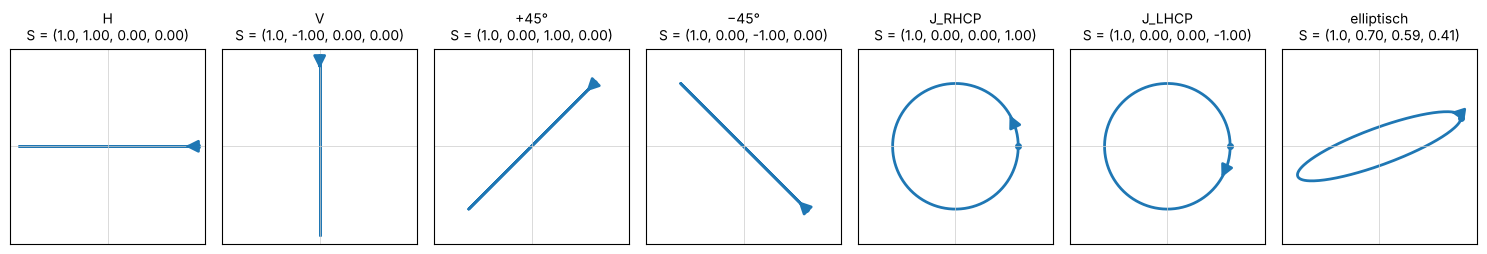

In [2]:
states = {"H": J.J_H, "V": J.J_V, "+45°": J.J_Lp45, "−45°": J.J_Lm45,
          "J_RHCP": J.J_RHCP, "J_LHCP": J.J_LHCP,
          "elliptisch": np.array([np.cos(0.4), np.sin(0.4)*np.exp(0.6j)])}
fig, axes = plt.subplots(1, len(states), figsize=(15, 2.9))
for ax, (name, E) in zip(axes, states.items()):
    S = M.stokes_from_complex_E(E)
    draw_ellipse(ax, E, title=f"{name}\nS = ({S[0]:.1f}, {S[1]:.2f}, {S[2]:.2f}, {S[3]:.2f})")
fig.tight_layout()

## 2. Malus' Gesetz und drei Polarisatoren

Ein Polarisator unter dem Winkel $\varphi$ zur Polarisationsrichtung lässt
$I = I_0\cos^2\varphi$ durch. Zwei gekreuzte Polarisatoren sperren alles. Stellt
man einen dritten unter $45°$ *dazwischen*, kommt wieder ein Viertel durch.
Mit $N$ Polarisatoren in gleichen Winkelschritten von $0°$ bis $90°$ ist die
Transmission $\cos^{2N}(\pi/2N)$ und strebt für $N \to \infty$ gegen eins: Die
Polarisation wird verlustfrei "mitgenommen".

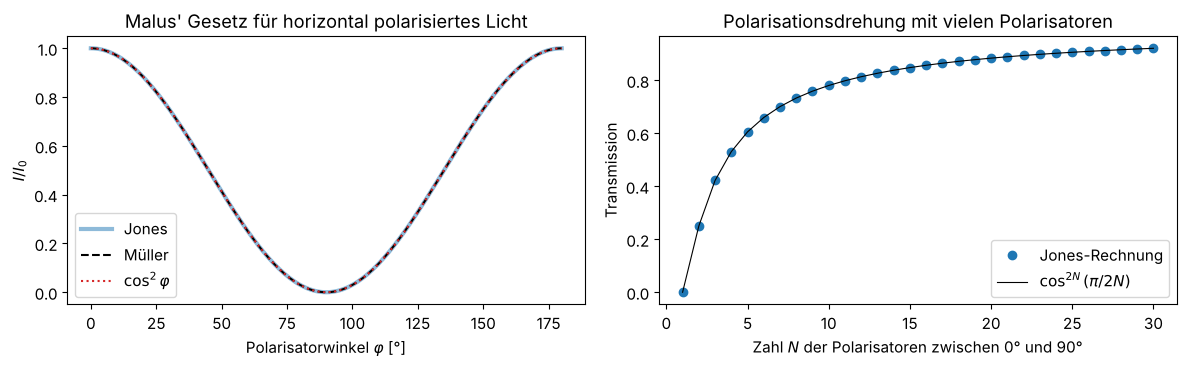

In [3]:
phi = np.linspace(0, np.pi, 181)
I_jones = [np.sum(np.abs(J.J_rot_polarizer(p) @ J.J_H)**2) for p in phi]
I_mueller = [(M.M_linear_polarizer(p) @ M.S_LHP)[0] for p in phi]

def chain_transmission(N):
    E = J.J_H.astype(complex)
    for p in np.linspace(0, np.pi/2, N + 1)[1:]:
        E = J.J_rot_polarizer(p) @ E
    return np.sum(np.abs(E)**2)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(phi/deg, I_jones, lw=3, alpha=0.5, label="Jones")
axes[0].plot(phi/deg, I_mueller, "k--", label="Müller")
axes[0].plot(phi/deg, np.cos(phi)**2, ":", color="C3", label="$\\cos^2\\varphi$")
axes[0].set_xlabel("Polarisatorwinkel $\\varphi$ [°]"); axes[0].set_ylabel("$I/I_0$"); axes[0].legend()
axes[0].set_title("Malus' Gesetz für horizontal polarisiertes Licht")
Ns = np.arange(1, 31)
axes[1].plot(Ns, [chain_transmission(N) for N in Ns], "o", label="Jones-Rechnung")
axes[1].plot(Ns, np.cos(np.pi/(2*Ns))**(2*Ns), "k-", lw=0.8, label="$\\cos^{2N}(\\pi/2N)$")
axes[1].set_xlabel("Zahl $N$ der Polarisatoren zwischen 0° und 90°"); axes[1].set_ylabel("Transmission")
axes[1].set_title("Polarisationsdrehung mit vielen Polarisatoren"); axes[1].legend()
fig.tight_layout()

## 3. Wellenplatten und die Poincaré-Kugel

Eine Wellenplatte verzögert die Komponente entlang der langsamen Achse um
$\delta$. Die $\lambda/2$-Platte ($\delta = \pi$) unter dem Winkel $\theta$ dreht
lineare Polarisation um $2\theta$. Die $\lambda/4$-Platte ($\delta = \pi/2$) unter
$45°$ macht aus linearer zirkulare Polarisation.

Auf der **Poincaré-Kugel** (Punkt $(S_1, S_2, S_3)/S_0$) wirkt jede Wellenplatte
als Drehung um ihre schnelle Achse (einen Punkt auf dem Äquator) um den Winkel
$\delta$. Dreht man eine $\lambda/4$-Platte vor horizontal polarisiertem Licht,
beschreibt der Ausgangszustand eine Acht.

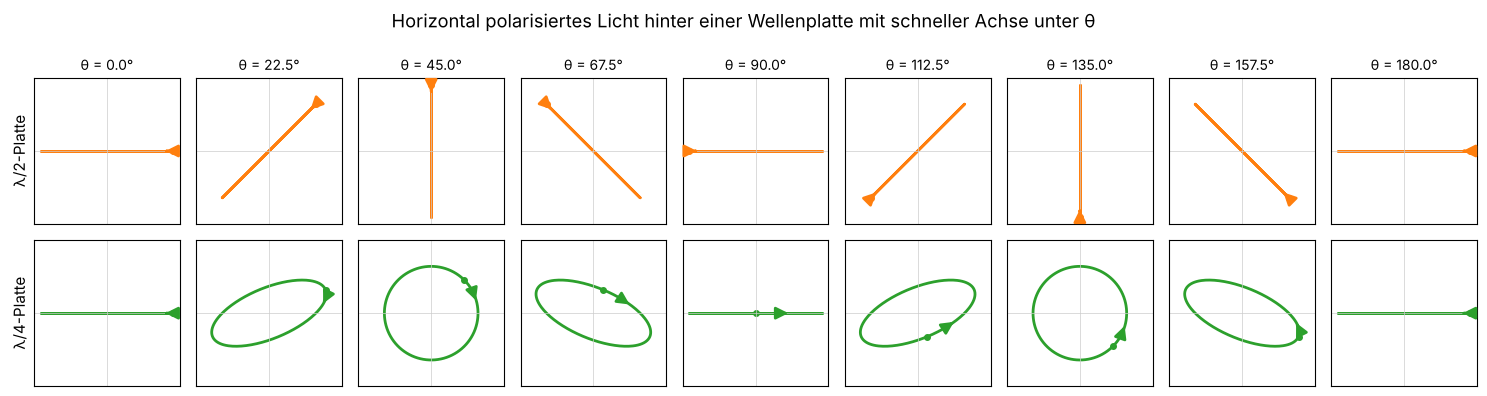

In [4]:
thetas = np.arange(0, 181, 22.5)*deg
fig, axes = plt.subplots(2, len(thetas), figsize=(15, 4.2))
for i, th in enumerate(thetas):
    draw_ellipse(axes[0, i], J.J_WP(np.pi, th) @ J.J_H, color="C1", title=f"θ = {th/deg:.1f}°")
    draw_ellipse(axes[1, i], J.J_WP(np.pi/2, th) @ J.J_H, color="C2")
axes[0, 0].set_ylabel("λ/2-Platte"); axes[1, 0].set_ylabel("λ/4-Platte")
fig.suptitle("Horizontal polarisiertes Licht hinter einer Wellenplatte mit schneller Achse unter θ")
fig.tight_layout()

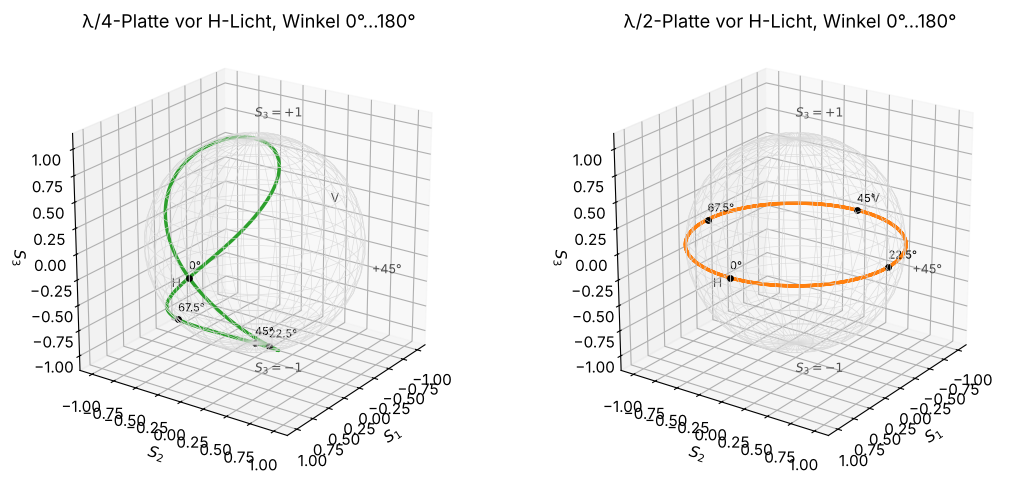

In [5]:
fig = plt.figure(figsize=(11, 5))
for j, (delta, name, c) in enumerate(((np.pi/2, "λ/4-Platte", "C2"), (np.pi, "λ/2-Platte", "C1"))):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    u, v = np.mgrid[0:2*np.pi:40j, 0:np.pi:20j]
    ax.plot_wireframe(np.cos(u)*np.sin(v), np.sin(u)*np.sin(v), np.cos(v), color="0.85", lw=0.4)
    th = np.linspace(0, np.pi, 400)
    S = np.array([M.M_retarder(t, delta) @ M.S_LHP for t in th])
    ax.plot(S[:, 1], S[:, 2], S[:, 3], color=c, lw=2.5)
    for t in (0, 22.5, 45, 67.5):
        s = M.M_retarder(t*deg, delta) @ M.S_LHP
        ax.scatter(s[1], s[2], s[3], color="k", s=15)
        ax.text(s[1], s[2], s[3] + 0.08, f"{t}°", fontsize=8)
    for (x, y, z, lab) in ((1.25, 0, 0, "H"), (-1.25, 0, 0, "V"), (0, 1.25, 0, "+45°"), (0, 0, 1.2, "$S_3=+1$"), (0, 0, -1.3, "$S_3=-1$")):
        ax.text(x, y, z, lab, fontsize=9, color="0.3")
    ax.set_xlabel("$S_1$"); ax.set_ylabel("$S_2$"); ax.set_zlabel("$S_3$")
    ax.set_box_aspect((1, 1, 1)); ax.view_init(elev=22, azim=35)
    ax.set_title(f"{name} vor H-Licht, Winkel 0°…180°")
fig.tight_layout()

Die λ/2-Platte führt den Zustand zweimal um den Äquator (lineare Polarisation,
Drehwinkel $2\theta$), die λ/4-Platte erreicht bei $\theta = \pm 45°$ die Pole
(zirkular).

## 4. Jones und Müller sind konsistent, aber Müller kann mehr

`M_from_jones()` wandelt jede Jones-Matrix in eine Müller-Matrix um. Für die
Elemente aus `mueller.py` ergibt das exakt dieselben Matrizen:

Polarisator 30°      max|M - M_from_jones(J)| = 1.1e-16
λ/4-Platte 20°       max|M - M_from_jones(J)| = 2.2e-16
Retarder δ=1, 70°    max|M - M_from_jones(J)| = 2.2e-16


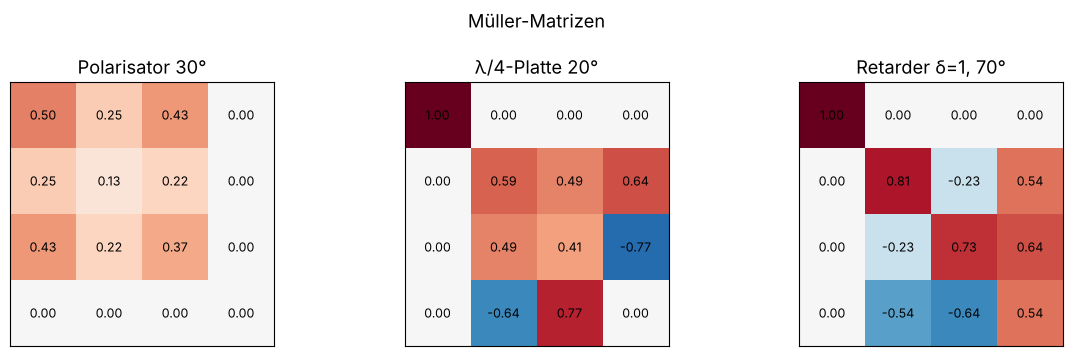

In [6]:
checks = {
    "Polarisator 30°": (M.M_linear_polarizer(30*deg), J.J_rot_polarizer(30*deg)),
    "λ/4-Platte 20°": (M.M_retarder(20*deg, np.pi/2), J.J_WP(np.pi/2, 20*deg)),
    "Retarder δ=1, 70°": (M.M_retarder(70*deg, 1.0), J.J_WP(1.0, 70*deg)),
}
for name, (Mm, Jm) in checks.items():
    print(f"{name:20s} max|M - M_from_jones(J)| = {np.max(np.abs(Mm - M.M_from_jones(Jm))):.1e}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, (Mm, _)) in zip(axes, checks.items()):
    ax.imshow(Mm, cmap="RdBu_r", vmin=-1, vmax=1)
    for (i, j), val in np.ndenumerate(Mm):
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(name)
fig.suptitle("Müller-Matrizen")
fig.tight_layout()

Was Jones nicht kann: **Depolarisation**. Ein Bündel, dessen Teilstrahlen
verschiedene Verzögerungen erfahren (z.B. durch eine raue oder verspannte
Platte), addiert sich inkohärent. Die Müller-Matrix ist dann der Mittelwert der
einzelnen Müller-Matrizen, und der Polarisationsgrad
$\mathrm{DOP} = \sqrt{S_1^2 + S_2^2 + S_3^2}/S_0$ sinkt unter eins.

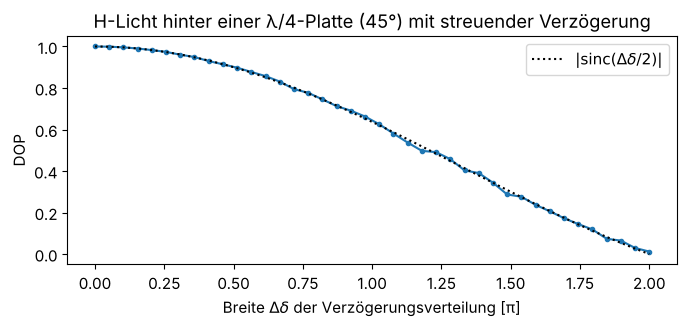

In [7]:
rng = np.random.default_rng(1)
spreads = np.linspace(0, 2*np.pi, 40)
dop = []
for spread in spreads:
    deltas = np.pi/2 + spread*(rng.random(2000) - 0.5)
    M_avg = np.mean([M.M_retarder(45*deg, d) for d in deltas], axis=0)
    dop.append(M.stokes_DOP(M_avg @ M.S_LHP))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(spreads/np.pi, dop, "o-", ms=3)
ax.plot(spreads/np.pi, np.abs(np.sinc(spreads/(2*np.pi))), "k:", label="$|\\mathrm{sinc}(\\Delta\\delta/2)|$")
ax.set_xlabel("Breite $\\Delta\\delta$ der Verzögerungsverteilung [π]"); ax.set_ylabel("DOP")
ax.set_title("H-Licht hinter einer λ/4-Platte (45°) mit streuender Verzögerung"); ax.legend()
fig.tight_layout()

## 5. Reflexion an Glas polarisiert

Unpolarisiertes Licht ($S = (1, 0, 0, 0)$) wird an Glas teilweise polarisiert
reflektiert, weil $R_s \neq R_p$. `M_reflection_dielectric(r_s, r_p)` erzeugt die
Müller-Matrix aus den Fresnel-Koeffizienten. Beim Brewster-Winkel ist das
reflektierte Licht vollständig s-polarisiert. Darauf beruhen Polarisationsbrillen,
die Reflexe auf Wasser und Straßen unterdrücken.

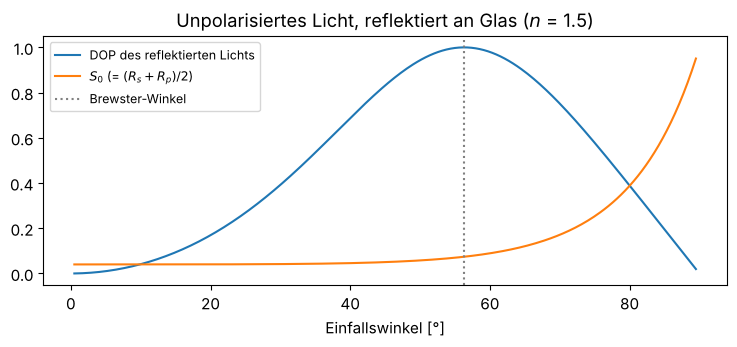

In [8]:
theta = np.linspace(0.5, 89.5, 300)*deg
n_glass = 1.5
S_refl = np.array([M.M_reflection_dielectric(itf.r_s(t, 1.0, n_glass), itf.r_p(t, 1.0, n_glass)) @ M.S_unpol
                   for t in theta])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(theta/deg, [M.stokes_DOP(S) for S in S_refl], label="DOP des reflektierten Lichts")
ax.plot(theta/deg, S_refl[:, 0], label="$S_0$ (= $(R_s + R_p)/2$)")
ax.axvline(itf.brewster_angle(1.0, n_glass)/deg, color="0.5", ls=":", label="Brewster-Winkel")
ax.set_xlabel("Einfallswinkel [°]"); ax.legend(fontsize=9)
ax.set_title("Unpolarisiertes Licht, reflektiert an Glas ($n$ = 1.5)")
fig.tight_layout()

## 6. Der Fresnel-Rhombus: eine λ/4-Platte aus Totalreflexion

Bei Totalreflexion erhalten s- und p-Anteil verschiedene Phasen (Notebook 03).
`M_TIR(phi, n)` ist die Müller-Matrix eines Retarders mit

$$\delta(\varphi) = 2\arctan\frac{\cos\varphi\sqrt{n^2\sin^2\varphi - 1}}{n\sin^2\varphi}.$$

Für Kronglas ($n = 1.51$) ist das Maximum knapp über $45°$. Fresnel wählte einen
Winkel mit $\delta = 45°$ und ließ das Licht im Rhombus **zweimal**
totalreflektieren: zusammen $90°$, also eine λ/4-Platte, die (anders als
doppelbrechende Platten) kaum von der Wellenlänge abhängt.

Der Vergleich mit $\arg r_s - \arg r_p$ aus `interfaces` zeigt, dass beide Module
dieselbe Konvention benutzen.

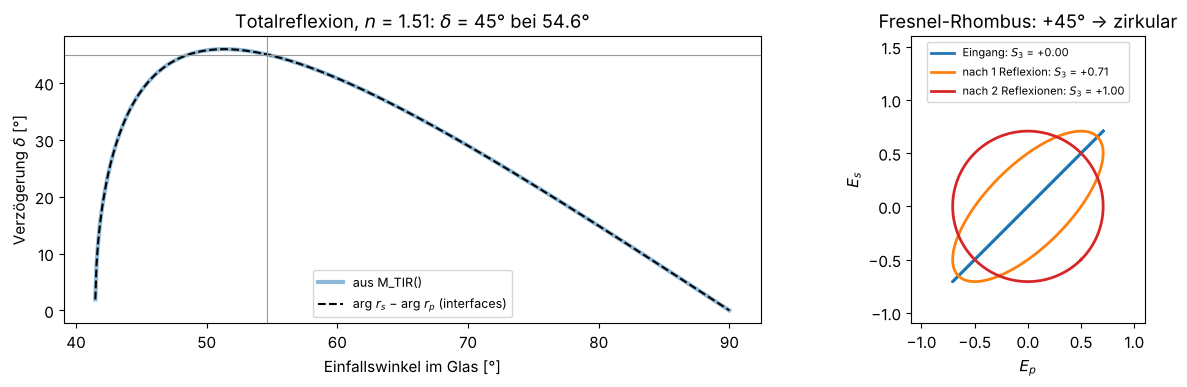

In [9]:
n_rhomb = 1.51
phi = np.linspace(np.arcsin(1/n_rhomb) + 1e-4, np.pi/2 - 1e-4, 500)
delta_M = np.array([np.arctan2(M.M_TIR(p, n_rhomb)[3, 2], M.M_TIR(p, n_rhomb)[2, 2]) for p in phi])
delta_F = np.angle(itf.r_s(phi, n_rhomb, 1.0)) - np.angle(itf.r_p(phi, n_rhomb, 1.0))
delta_F = np.mod(delta_F + np.pi, 2*np.pi) - np.pi

# Winkel mit delta = 45° (der größere der beiden Lösungen, wie bei Fresnel):
i_max = np.argmax(delta_M)
phi_45 = phi[i_max:][np.argmin(np.abs(delta_M[i_max:] - np.pi/4))]

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].plot(phi/deg, delta_M/deg, lw=3, alpha=0.5, label="aus M_TIR()")
axes[0].plot(phi/deg, delta_F/deg, "k--", label="arg $r_s$ − arg $r_p$ (interfaces)")
axes[0].axhline(45, color="0.6", lw=0.8); axes[0].axvline(phi_45/deg, color="0.6", lw=0.8)
axes[0].set_xlabel("Einfallswinkel im Glas [°]"); axes[0].set_ylabel("Verzögerung $\\delta$ [°]")
axes[0].set_title(f"Totalreflexion, $n$ = {n_rhomb}: $\\delta$ = 45° bei {phi_45/deg:.1f}°"); axes[0].legend(fontsize=9)

# Licht unter 45° zur Einfallsebene (p = x, s = y): zwei Totalreflexionen
S_in = M.S_Lp45P
S_one = M.M_TIR(phi_45, n_rhomb) @ S_in
S_two = M.M_TIR(phi_45, n_rhomb) @ S_one
for S, name, c in ((S_in, "Eingang", "C0"), (S_one, "nach 1 Reflexion", "C1"), (S_two, "nach 2 Reflexionen", "C3")):
    # Stokes -> ein passender Jones-Vektor zum Zeichnen:
    psi = 0.5*np.arctan2(S[2], S[1]); chi = 0.5*np.arcsin(np.clip(S[3]/S[0], -1, 1))
    E = np.array([np.cos(psi)*np.cos(chi) - 1j*np.sin(psi)*np.sin(chi),
                  np.sin(psi)*np.cos(chi) + 1j*np.cos(psi)*np.sin(chi)])
    wt = np.linspace(0, 2*np.pi, 200)
    axes[1].plot(np.real(E[0]*np.exp(-1j*wt)), np.real(E[1]*np.exp(-1j*wt)), color=c, lw=2,
                 label=f"{name}: $S_3$ = {S[3]:+.2f}")
axes[1].set_aspect("equal"); axes[1].set_xlim(-1.1, 1.1); axes[1].set_ylim(-1.1, 1.6)
axes[1].set_xlabel("$E_p$"); axes[1].set_ylabel("$E_s$"); axes[1].legend(fontsize=8, loc="upper center")
axes[1].set_title("Fresnel-Rhombus: +45° → zirkular")
fig.tight_layout()

## 7. Reflexion an Metall

`M_reflection_metal()` berechnet die Müller-Matrix für ein Metall mit
komplexem Brechungsindex. Linear unter $45°$ polarisiertes Licht wird
elliptisch; bei einem Einfallswinkel nahe dem Hauptwinkel (Notebook 03) ist die
Verzögerung $90°$ und die Ellipse steht aufrecht.

Dass bei $\theta = 0$ aus $+45°$ scheinbar $-45°$ wird, ist kein physikalischer
Effekt, sondern die übliche Spiegelung: Die Koordinaten $(p, s)$ beziehen sich
auf den reflektierten Strahl, der in die Gegenrichtung läuft (deshalb gilt in
der Hecht-Konvention $r_p = -r_s$ bei senkrechtem Einfall).

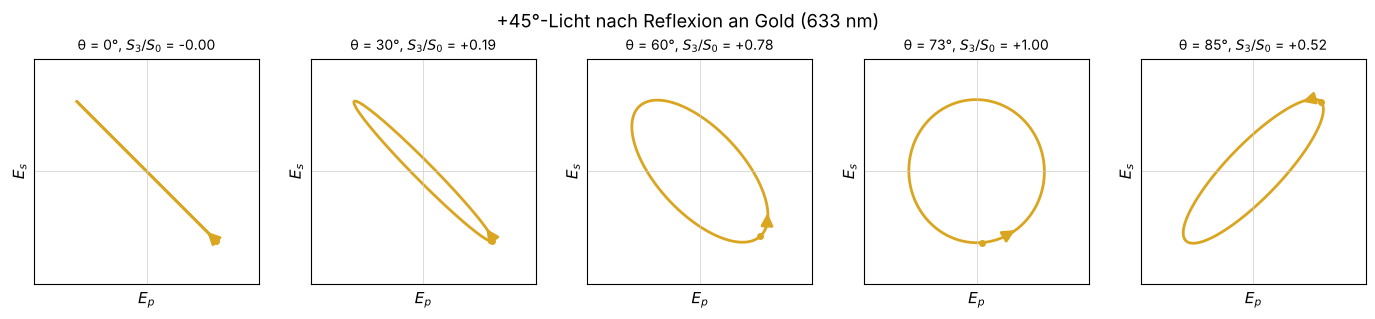

In [10]:
n_Au = 0.18 + 3.0j
angles = (0, 30, 60, 73, 85)
fig, axes = plt.subplots(1, len(angles), figsize=(14, 3))
for ax, a in zip(axes, angles):
    S = M.M_reflection_metal(a*deg, n_Au) @ M.S_Lp45P
    psi = 0.5*np.arctan2(S[2], S[1]); chi = 0.5*np.arcsin(np.clip(S[3]/S[0], -1, 1))
    E = np.sqrt(S[0])*np.array([np.cos(psi)*np.cos(chi) - 1j*np.sin(psi)*np.sin(chi),
                                np.sin(psi)*np.cos(chi) + 1j*np.cos(psi)*np.sin(chi)])
    draw_ellipse(ax, E, color="goldenrod", title=f"θ = {a}°, $S_3/S_0$ = {S[3]/S[0]:+.2f}")
    ax.set_xlabel("$E_p$"); ax.set_ylabel("$E_s$")
fig.suptitle("+45°-Licht nach Reflexion an Gold (633 nm)")
fig.tight_layout()